In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("Dry_Bean_Dataset.csv")

In [3]:
df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610291.00,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638018.00,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.11,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645884.00,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620134.00,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [4]:
df.Class.unique()

array(['SEKER', 'BARBUNYA', 'BOMBAY', 'CALI', 'HOROZ', 'SIRA', 'DERMASON'],
      dtype=object)

In [5]:
df.columns

Index(['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength',
       'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent',
       'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2',
       'ShapeFactor3', 'ShapeFactor4', 'Class'],
      dtype='object')

In [6]:
df.shape

(13611, 17)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  object 
dtypes: float64(1

In [8]:
df.describe()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000000,1.361100e+04,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,7.729110e+05,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,3.238848e+05,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,5.536000e+02,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,6.769955e+05,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,7.722730e+05,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,9.555000e+05,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1.921685e+06,738.860153,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


In [9]:
df.isnull().sum()

Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(68)

In [11]:
df = df.drop_duplicates()

In [12]:
df["Class"].value_counts()

Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1860
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

In [13]:
X = df.drop("Class", axis=1)

y = df["Class"]

In [14]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

y = le.fit_transform(y)

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y)

In [16]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## 1.LogisticRegression

In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

In [30]:
LR = LogisticRegression(random_state=42)

LR.fit(X_train, y_train)

LogisticRegression(random_state=42)

In [31]:
y_pred = LR.predict(X_test)

In [32]:
print("Training Accuracy :", LR.score(X_train, y_train))
print("Testing Accuracy  :", LR.score(X_test, y_test))

Training Accuracy : 0.9256045781798043
Testing Accuracy  : 0.9180509413067552


In [33]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy Score :", accuracy)

Accuracy Score : 0.9180509413067552


In [34]:
print(classification_report(
    y_test,
    y_pred,
    target_names=le.classes_
))

              precision    recall  f1-score   support

    BARBUNYA       0.93      0.89      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.91      0.94      0.93       326
    DERMASON       0.92      0.91      0.91       709
       HOROZ       0.96      0.94      0.95       372
       SEKER       0.93      0.94      0.94       406
        SIRA       0.86      0.88      0.87       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



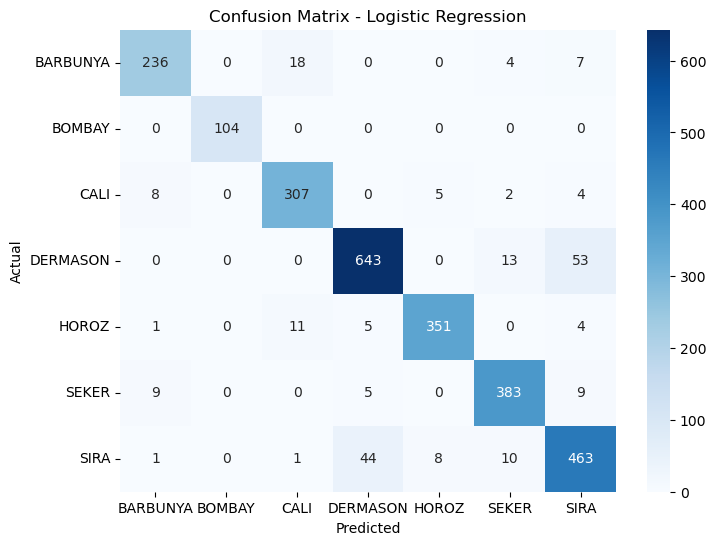

In [35]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=le.classes_,
    yticklabels=le.classes_)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Logistic Regression")

plt.show()

## 2.DecisionTreeClassifier

In [43]:
from sklearn.tree import DecisionTreeClassifier

In [44]:
DT = DecisionTreeClassifier(random_state=42,max_depth=20,min_samples_split=10,min_samples_leaf=4)

DT.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=20, min_samples_leaf=4, min_samples_split=10,
                       random_state=42)

In [45]:
y_pred = DT.predict(X_test)

In [46]:
print("Training Accuracy :", DT.score(X_train, y_train))
print("Testing Accuracy  :", DT.score(X_test, y_test))

Training Accuracy : 0.9613254568949603
Testing Accuracy  : 0.8973791066814323


In [47]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy Score :", accuracy)

Accuracy Score : 0.8973791066814323


In [48]:
print(classification_report(
    y_test,
    y_pred,
    target_names=le.classes_
))

              precision    recall  f1-score   support

    BARBUNYA       0.88      0.92      0.90       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.90      0.91       326
    DERMASON       0.88      0.90      0.89       709
       HOROZ       0.96      0.92      0.94       372
       SEKER       0.94      0.93      0.93       406
        SIRA       0.83      0.82      0.82       527

    accuracy                           0.90      2709
   macro avg       0.91      0.91      0.91      2709
weighted avg       0.90      0.90      0.90      2709



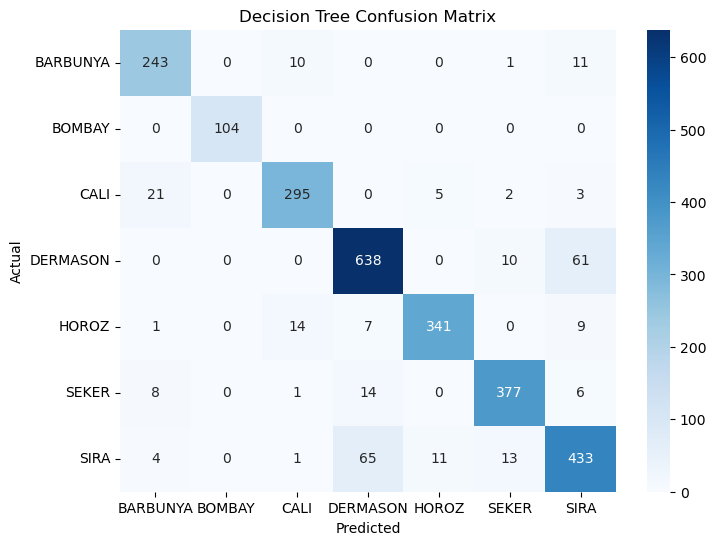

In [49]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Confusion Matrix")

plt.show()

## 3.Random Forest

In [17]:
from sklearn.ensemble import RandomForestClassifier

In [18]:
RF = RandomForestClassifier(random_state=42,max_depth=20,min_samples_leaf=4,min_samples_split=10,n_estimators=200)

RF.fit(X_train, y_train)

RandomForestClassifier(max_depth=20, min_samples_leaf=4, min_samples_split=10,
                       n_estimators=200, random_state=42)

In [19]:
y_pred = RF.predict(X_test)

In [20]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.9150978220745662


In [22]:
print("Training Accuracy :", RF.score(X_train, y_train))
print("Testing Accuracy  :", RF.score(X_test, y_test))

Training Accuracy : 0.9653867454310504
Testing Accuracy  : 0.9150978220745662


## 4.KNN

In [17]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [18]:
KNN = KNeighborsClassifier()

KNN.fit(X_train, y_train)

KNeighborsClassifier()

In [19]:
y_pred = KNN.predict(X_test)

  File "C:\Users\adhur\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\adhur\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\adhur\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\adhur\anaconda3\Lib\subprocess.

In [20]:
print("Training Accuracy :", KNN.score(X_train, y_train))
print("Testing Accuracy  :", KNN.score(X_test, y_test))

Training Accuracy : 0.9413882222632454
Testing Accuracy  : 0.9102990033222591


In [21]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy Score :", accuracy)

Accuracy Score : 0.9102990033222591


In [22]:
print(classification_report(
    y_test,
    y_pred,
    target_names=le.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.92      0.87      0.89       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.88      0.93      0.90       326
    DERMASON       0.90      0.92      0.91       709
       HOROZ       0.96      0.93      0.95       372
       SEKER       0.94      0.93      0.94       406
        SIRA       0.86      0.86      0.86       527

    accuracy                           0.91      2709
   macro avg       0.92      0.92      0.92      2709
weighted avg       0.91      0.91      0.91      2709



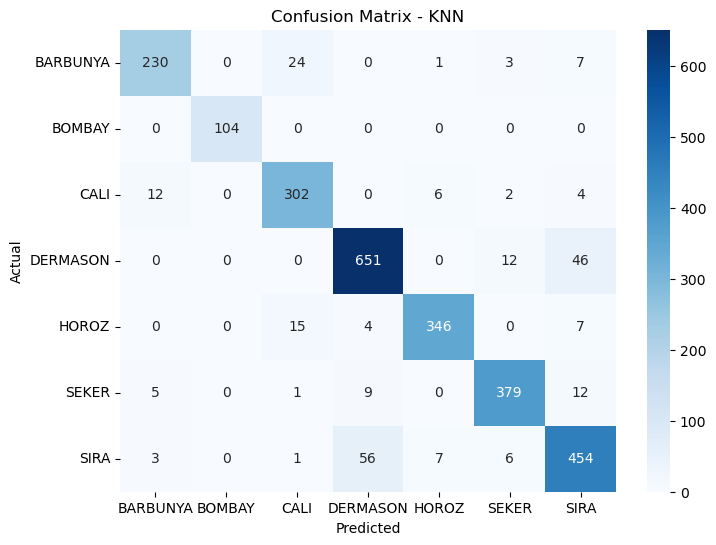

In [23]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - KNN")

plt.show()

## 5.Naive Bayes

In [32]:
from sklearn.naive_bayes import GaussianNB

In [33]:
NB = GaussianNB()

NB.fit(X_train, y_train)

GaussianNB()

In [34]:
y_pred = NB.predict(X_test)

In [35]:
print("Training Accuracy :", NB.score(X_train, y_train))
print("Testing Accuracy  :", NB.score(X_test, y_test))

Training Accuracy : 0.8967140483662543
Testing Accuracy  : 0.8984865263935031


In [36]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy Score :", accuracy)

Accuracy Score : 0.8984865263935031


In [37]:
print(classification_report(
    y_test,
    y_pred,
    target_names=le.classes_))

              precision    recall  f1-score   support

    BARBUNYA       0.89      0.79      0.84       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.86      0.93      0.89       326
    DERMASON       0.94      0.86      0.90       709
       HOROZ       0.95      0.95      0.95       372
       SEKER       0.92      0.94      0.93       406
        SIRA       0.82      0.90      0.85       527

    accuracy                           0.90      2709
   macro avg       0.91      0.91      0.91      2709
weighted avg       0.90      0.90      0.90      2709



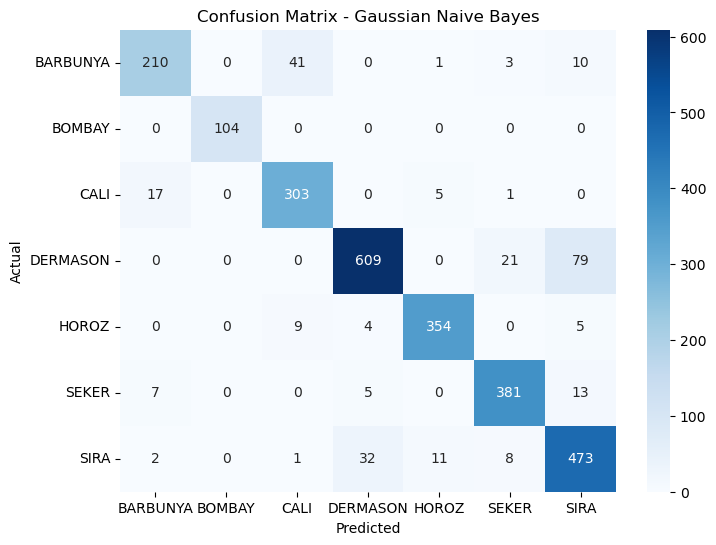

In [38]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=le.classes_,
    yticklabels=le.classes_)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Gaussian Naive Bayes")

plt.show()

## 6.SVM

In [39]:
from sklearn.svm import SVC

In [40]:
SVM = SVC(random_state=42)

SVM.fit(X_train, y_train)

SVC(random_state=42)

In [41]:
y_pred = SVM.predict(X_test)

In [42]:
print("Training Accuracy :", SVM.score(X_train, y_train))
print("Testing Accuracy  :", SVM.score(X_test, y_test))

Training Accuracy : 0.934742477386007
Testing Accuracy  : 0.9217423403469915


In [43]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy Score :", accuracy)

Accuracy Score : 0.9217423403469915


In [44]:
print(classification_report(
    y_test,
    y_pred,
    target_names=le.classes_
))

              precision    recall  f1-score   support

    BARBUNYA       0.94      0.89      0.92       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.92      0.94      0.93       326
    DERMASON       0.92      0.91      0.92       709
       HOROZ       0.96      0.94      0.95       372
       SEKER       0.94      0.95      0.95       406
        SIRA       0.86      0.88      0.87       527

    accuracy                           0.92      2709
   macro avg       0.94      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



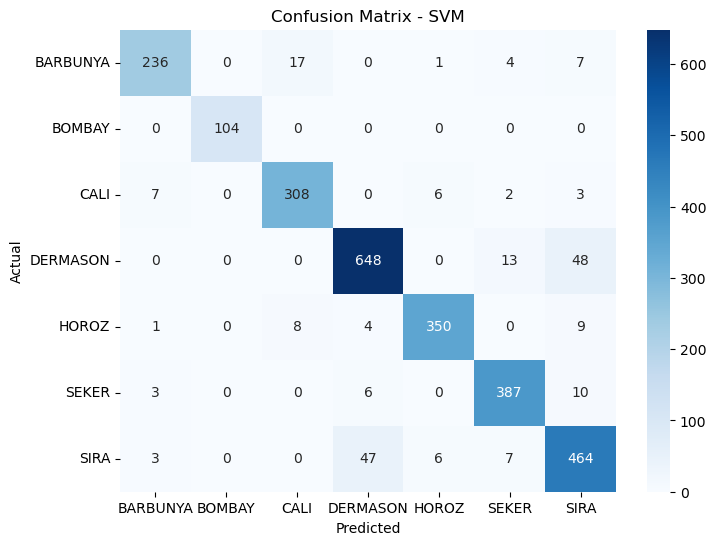

In [45]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - SVM")

plt.show()

In [46]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    SVM,
    X,
    y,
    cv=5)

print("Cross Validation Scores :", cv_scores)
print("Average CV Score :", cv_scores.mean())

Cross Validation Scores : [0.32668882 0.62236988 0.73643411 0.75812408 0.26920236]
Average CV Score : 0.5425638483898249


## 7.GradientBoostingClassifier

In [48]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [49]:
GB = GradientBoostingClassifier(random_state=42)

GB.fit(X_train, y_train)

GradientBoostingClassifier(random_state=42)

In [50]:
y_pred = GB.predict(X_test)

In [51]:
print("Training Accuracy :", GB.score(X_train, y_train))
print("Testing Accuracy  :", GB.score(X_test, y_test))

Training Accuracy : 0.9640945172604762
Testing Accuracy  : 0.9158361018826136


In [52]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy Score :", accuracy)

Accuracy Score : 0.9158361018826136


In [53]:
print(classification_report(
    y_test,
    y_pred,
    target_names=le.classes_
))

              precision    recall  f1-score   support

    BARBUNYA       0.93      0.89      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.93      0.94      0.93       326
    DERMASON       0.91      0.92      0.91       709
       HOROZ       0.95      0.94      0.95       372
       SEKER       0.95      0.95      0.95       406
        SIRA       0.85      0.86      0.85       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



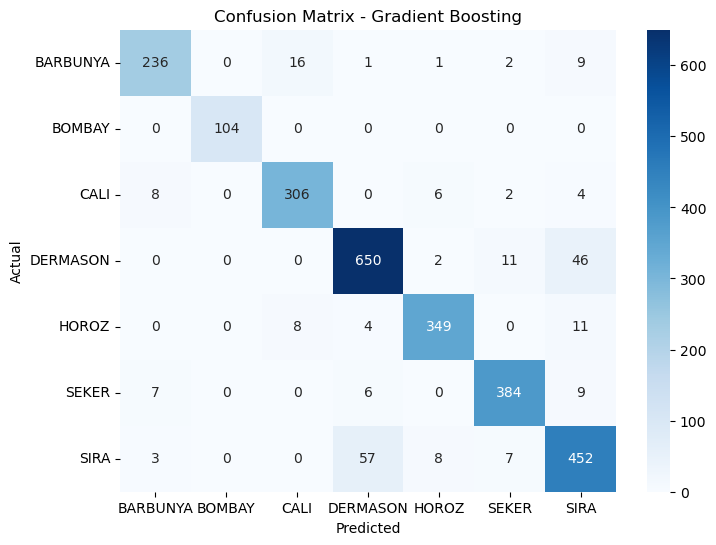

In [54]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Gradient Boosting")

plt.show()

In [55]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    GB,
    X,
    y,
    cv=5)

print("Cross Validation Scores :", cv_scores)
print("Average CV Score :", cv_scores.mean())

Cross Validation Scores : [0.48098929 0.84385382 0.93724622 0.78914328 0.36742984]
Average CV Score : 0.6837324897096118
